# How `build_3d_segmentation.py` works (version 1)

`build_3d_segmentation.py` builds **one 3D label volume of a whole NextBrain hemisphere** from the
registered histology blocks of a case. This notebook runs every step of the script on Case 1
(P57-16), on real data, and shows what each step does.

The idea in one sentence: every tissue block already comes with a 3D label volume and a header that
says where it sits in the MRI space, so the script only has to **paste all blocks onto one common
grid** (a mosaic), sampling each block with nearest neighbour.

Contents:
1. The inputs: what a block looks like
2. The output grid (`target_grid`)
3. Where each block falls in the output grid (bounding box)
4. From an output voxel to a block voxel (the affine `M`)
5. Resampling one whole block
6. Overlapping blocks: who wins
7. The complete result and its limitations

The notebook reads the data but **writes nothing**. It takes about 2 minutes to run.

In [1]:
import os, sys, csv, itertools, time
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon
from scipy import ndimage as ndi
from scipy.spatial import ConvexHull

%matplotlib inline
plt.rcParams["figure.dpi"] = 90

HERE = os.path.abspath(".")
sys.path.insert(0, HERE)
import build_3d_segmentation as V1           # the script explained here

CASE_DIR = os.path.join(HERE, "..", "NextBrain-Case-1", "P57-16")
LUT_FILE = os.path.join(HERE, "..", "..", "3dAtlas", "lut.freeview.txt")
OUT_V1 = os.path.join(HERE, "outputs", "P57-16_seg_0.2mm.nii.gz")
RES = 0.2                                    # output voxel size in mm
EXAMPLE = "8"                                # block used in most examples (A2.3)

In [2]:
# ---- display helpers ---------------------------------------------------------------------
BG = (0.45, 0.45, 0.45)      # background is drawn mid-grey: white matter is almost white and the
                             # ventricle almost black in the NextBrain colour table

def load_lut(path):
    names, rgb = {}, np.full((4096, 3), 0.5)
    for line in open(path):
        p = line.split()
        if len(p) >= 5 and p[0].isdigit():
            names[int(p[0])] = p[1]
            rgb[int(p[0])] = [int(v) / 255 for v in p[2:5]]
    rgb[0] = BG
    return names, rgb

NAMES, RGB = load_lut(LUT_FILE)

def show_lab(ax, a2d, extent=None, title=None, aspect="equal"):
    """Draw a 2D label image. First array axis is drawn horizontally."""
    ax.imshow(RGB[a2d.T], origin="lower", interpolation="nearest", extent=extent, aspect=aspect)
    if title: ax.set_title(title, fontsize=10)

def show_img(ax, a2d, extent=None, title=None, **kw):
    im = ax.imshow(a2d.T, origin="lower", interpolation="nearest", extent=extent, **kw)
    if title: ax.set_title(title, fontsize=10)
    return im

def overlay(ax, mask2d, color, extent=None, alpha=0.9):
    rgba = np.zeros(mask2d.T.shape + (4,)); rgba[mask2d.T] = (*plt.matplotlib.colors.to_rgb(color), alpha)
    ax.imshow(rgba, origin="lower", interpolation="nearest", extent=extent)

## 1. The inputs: what a block looks like

A NextBrain hemisphere was cut in three steps, each one finer than the previous. These three words
are used in the whole notebook:

| word | what it is | size | in the data |
|---|---|---|---|
| **slab** | one thick slice of the whole hemisphere, cut with a knife | ~1 cm thick, as wide as the brain | only a name: `A2` |
| **block** | one piece of a slab, small enough for the microtome. A slab gives 1 to 4 blocks | a few cm wide, ~1 cm thick (the thickness of its slab) | one folder: `labels_blocks/8/` = block `A2.3` |
| **section** | one thin histology slice of a block, the image that was segmented | 0.1 mm pixels, one section every 0.33-0.8 mm | one index of the third axis of `LABELS.nii.gz` |

So: hemisphere → slabs → blocks → sections. The name of a block says where it comes from:
`A2.3` is **block 3 of slab A2**. The letter is the region (`A` anterior cerebrum, `P` posterior
cerebrum, `B` brainstem, `C` cerebellum) and `block2slab_mapping.csv` links the folder number to
the name (folder `8` → `A2.3`). The script never uses slabs: it works block by block. Slabs only
help to understand the figures (step 3 shows them).

### How the hemisphere was cut

(From the README of the case and the Methods of the NextBrain paper.)

1. **MRI first.** Before any cut, the whole hemisphere was scanned at 0.4 mm. This MRI is the only
   image of the brain in one piece, so everything is registered to it.
2. **Slabs, with a knife.** The hemisphere was separated into cerebrum, cerebellum and brainstem,
   and each part was cut into 10 mm thick slices: coronal for the cerebrum, sagittal for the
   cerebellum, axial for the brainstem.
3. **Blocks, with a knife.** A coronal slab of the cerebrum is larger than the standard cassette of
   the laboratory (74 x 52 mm), so it was cut into as many pieces as needed.
4. **Sections, with a microtome.** Each block was embedded in paraffin and cut completely into
   25 µm (0.025 mm) slices: about 400 cuts for a 10 mm block. **Only one of every N was kept**: it
   was stained (LFB), scanned and labelled. The others were discarded, because staining and
   labelling 400 slices per block is not feasible.
   - N = 10 → one section every **0.25 mm**, for blocks with subcortical structures, brainstem and
     medial cerebellum (small nuclei need dense sampling);
   - N = 20 → one section every **0.50 mm**, for all the other blocks (cortex and white matter
     change slowly).

The drawing below is a schematic of these cuts (it is not made from the data).

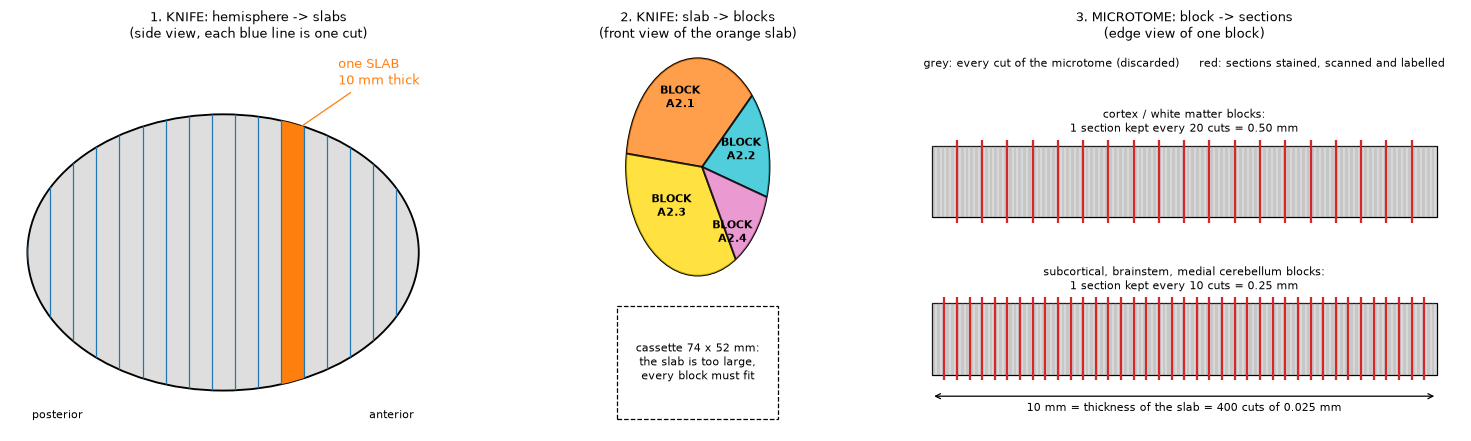

In [3]:
# Schematic drawing (no data is read here): the three cuts, from the hemisphere to the sections.
from matplotlib.patches import Ellipse, Wedge
fig, axs = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw=dict(width_ratios=[1.3, 0.9, 1.5]))

ax = axs[0]                                                    # 1) hemisphere seen from the side
brain = Ellipse((85, 60), 170, 120, fc="0.87", ec="k", lw=1.5); ax.add_patch(brain)
one = Rectangle((110, 0), 10, 120, fc="tab:orange", ec="none"); ax.add_patch(one); one.set_clip_path(brain)
for x in np.arange(0, 171, 10):
    ln, = ax.plot([x, x], [0, 120], color="tab:blue", lw=1); ln.set_clip_path(brain)
ax.annotate("one SLAB\n10 mm thick", xy=(115, 112), xytext=(135, 133), ha="left", fontsize=10, color="tab:orange",
            arrowprops=dict(arrowstyle="->", color="tab:orange"))
ax.text(2, -12, "posterior", fontsize=9); ax.text(168, -12, "anterior", fontsize=9, ha="right")
ax.set_xlim(-8, 200); ax.set_ylim(-18, 150)
ax.set_title("1. KNIFE: hemisphere -> slabs\n(side view, each blue line is one cut)", fontsize=10)

ax = axs[1]                                                    # 2) one slab seen from the front
face = Ellipse((0, 30), 66, 100, fc="none", ec="k", lw=1.5); ax.add_patch(face)
for (a0, a1), col, name, (tx, ty) in zip([(55, 170), (-25, 55), (170, 290), (290, 335)],
                                         ["tab:orange", "tab:cyan", "gold", "tab:pink"], ["1", "2", "3", "4"],
                                         [(-8, 32), (20, 8), (-12, -18), (16, -30)]):
    w = Wedge((2, 30), 80, a0, a1, fc=col, ec="k", lw=1.5, alpha=0.75); ax.add_patch(w); w.set_clip_path(face)
    ax.text(tx, ty + 30, f"BLOCK\nA2.{name}", ha="center", va="center", fontsize=9, weight="bold")
ax.add_patch(Rectangle((-37, -86), 74, 52, fill=False, ec="k", ls="--"))
ax.text(0, -60, "cassette 74 x 52 mm:\nthe slab is too large,\nevery block must fit", ha="center", va="center", fontsize=9)
ax.set_xlim(-55, 55); ax.set_ylim(-92, 86)
ax.set_title("2. KNIFE: slab -> blocks\n(front view of the orange slab)", fontsize=10)

ax = axs[2]                                                    # 3) one block seen from its edge
for y0, N, txt in [(2.2, 20, "cortex / white matter blocks:\n1 section kept every 20 cuts = 0.50 mm"),
                   (0.0, 10, "subcortical, brainstem, medial cerebellum blocks:\n1 section kept every 10 cuts = 0.25 mm")]:
    ax.add_patch(Rectangle((0, y0), 10, 1, fc="0.93", ec="k"))
    cuts = np.arange(0.025, 10, 0.025)
    ax.vlines(cuts, y0, y0 + 1, color="0.5", lw=0.3)                       # all the 25 um cuts
    ax.vlines(cuts[N - 1::N], y0 - 0.08, y0 + 1.08, color="tab:red", lw=1.8)   # the sections that were kept
    ax.text(5, y0 + 1.14, txt, ha="center", va="bottom", fontsize=9)
ax.annotate("", xy=(0, -0.3), xytext=(10, -0.3), arrowprops=dict(arrowstyle="<->"))
ax.text(5, -0.38, "10 mm = thickness of the slab = 400 cuts of 0.025 mm", ha="center", va="top", fontsize=9)
ax.text(5, 4.3, "grey: every cut of the microtome (discarded)     red: sections stained, scanned and labelled",
        ha="center", fontsize=8.5)
ax.set_xlim(-0.5, 10.5); ax.set_ylim(-0.8, 4.6)
ax.set_title("3. MICROTOME: block -> sections\n(edge view of one block)", fontsize=10)
for ax in axs[:2]: ax.set_aspect("equal")
for ax in axs: ax.axis("off")
plt.tight_layout(); plt.show()

So a block is a **stack of a few very detailed images with empty space between them**: 17-20
sections for the 0.50 mm blocks, 35-41 for the 0.25 mm blocks. Each section was registered to the
MRI of the hemisphere.

For each block the case repository gives `labels_blocks/<N>/LABELS.nii.gz`:
- a 3D array where **each index along the third axis is one histology section**;
- in-plane pixels of 0.1 mm, but sections far apart (0.33 to 0.8 mm);
- a header affine that maps the block voxels to millimetres **in the space of
  `mri_rotated/mri.nii.gz`**. This affine is the result of the registration; the script trusts it.

In [4]:
blocks_dir = os.path.join(CASE_DIR, "labels_blocks")
blocks = sorted((b for b in os.listdir(blocks_dir)
                 if os.path.exists(os.path.join(blocks_dir, b, "LABELS.nii.gz"))), key=int)
block_name = dict(csv.reader(open(os.path.join(CASE_DIR, "block2slab_mapping.csv"))))
print(len(blocks), "blocks")

img = nib.load(os.path.join(blocks_dir, EXAMPLE, "LABELS.nii.gz"))
lab = np.asanyarray(img.dataobj)
pix = np.linalg.norm(img.affine[:3, 0]); dz = np.linalg.norm(img.affine[:3, 2])
print(f"\nblock {EXAMPLE} ({block_name[EXAMPLE]}): array shape {lab.shape}  ->  {lab.shape[2]} sections")
print(f"  in-plane pixel {pix:.3f} mm, distance between sections {dz:.2f} mm")
print(f"  size in mm: {lab.shape[0]*pix:.0f} x {lab.shape[1]*pix:.0f} in-plane, {lab.shape[2]*dz:.1f} thick")
print("  labels:", {int(l): NAMES.get(int(l), "?") for l in np.unique(lab) if l})
print("  affine (block voxel -> mm in MRI space):\n", np.round(img.affine, 3))

45 blocks

block 8 (A2.3): array shape (585, 836, 18)  ->  18 sections
  in-plane pixel 0.100 mm, distance between sections 0.72 mm
  size in mm: 58 x 84 in-plane, 12.9 thick
  labels: {7: 'white_matter_of_forebrain', 48: 'head_of_caudate', 50: 'anterior_horn_of_lateral_ventricle', 68: 'septum_pellucidum', 79: 'putamen', 99: 'anterior_olfactory_nucleus', 100: 'olfactory_tubercle', 101: 'core_of_nucleus_accumbens', 102: 'claustrum', 113: 'lateral_olfactory_stria', 114: 'optic_nerve', 119: 'external_segment_of_globus_pallidus', 2012: 'ctx-rh-lateralorbitofrontal', 2014: 'ctx-rh-medialorbitofrontal', 2018: 'ctx-rh-parsopercularis', 2035: 'ctx-rh-insula'}
  affine (block voxel -> mm in MRI space):
 [[ 6.8000e-02  7.5000e-02  3.2000e-02 -6.2861e+01]
 [-2.5000e-02  1.7000e-02  6.8900e-01  2.4116e+01]
 [-6.9000e-02  6.4000e-02 -2.0000e-01 -4.1408e+01]
 [ 0.0000e+00  0.0000e+00  0.0000e+00  1.0000e+00]]


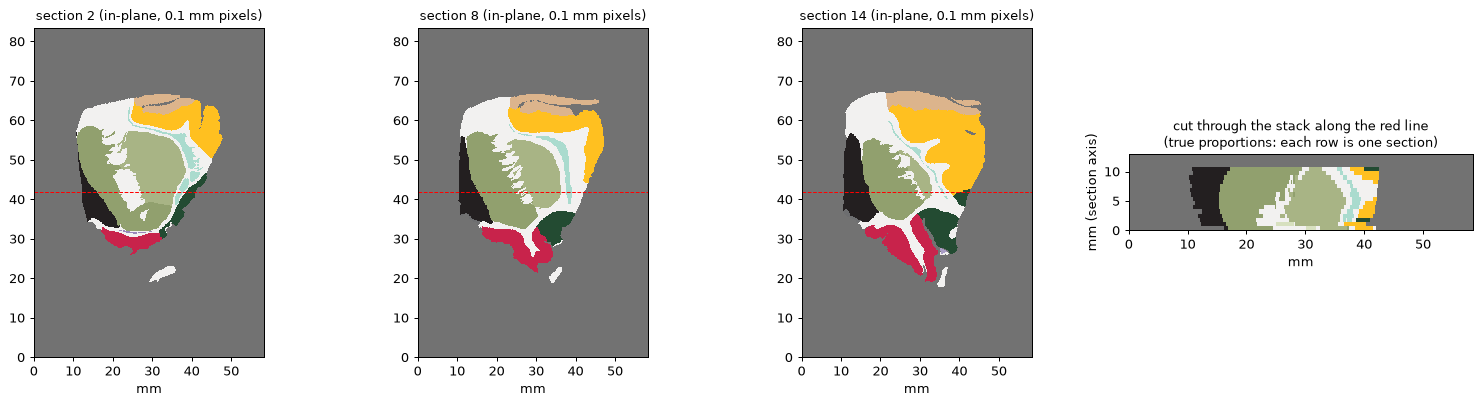

In [5]:
fig, axs = plt.subplots(1, 4, figsize=(17, 4.6))
for ax, k in zip(axs[:3], (2, 8, 14)):
    show_lab(ax, lab[:, :, k], extent=[0, lab.shape[0]*pix, 0, lab.shape[1]*pix], title=f"section {k} (in-plane, 0.1 mm pixels)")
    ax.set_xlabel("mm"); ax.axhline(lab.shape[1]*pix/2, color="r", lw=0.8, ls="--")
j0 = lab.shape[1] // 2
show_lab(axs[3], lab[:, j0, :], extent=[0, lab.shape[0]*pix, 0, lab.shape[2]*dz],
         title="cut through the stack along the red line\n(true proportions: each row is one section)")
axs[3].set_xlabel("mm"); axs[3].set_ylabel("mm (section axis)")
plt.tight_layout(); plt.show()

The last panel is the important one: a block is a **thin stack of very detailed sections**. In-plane
there is a pixel every 0.1 mm, but along the section axis there is only one sample every ~0.7 mm.
Anything the script produces between two sections has to be invented.

All the blocks of the case:

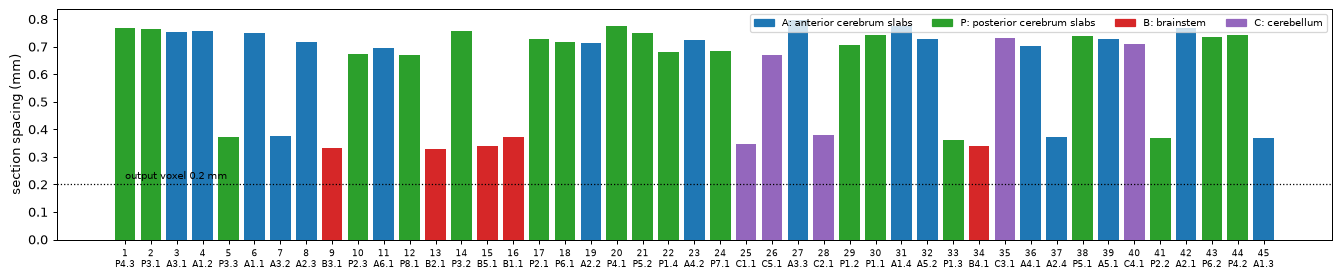

13 blocks have sections every 0.33-0.38 mm, 32 blocks every 0.67-0.80 mm
total number of sections: 1049


In [6]:
info = []
for b in blocks:
    im = nib.load(os.path.join(blocks_dir, b, "LABELS.nii.gz"))
    info.append((b, block_name[b], im.shape[2], np.linalg.norm(im.affine[:3, 2])))
letters = {"A": "tab:blue", "P": "tab:green", "B": "tab:red", "C": "tab:purple"}
fig, ax = plt.subplots(figsize=(15, 3.2))
ax.bar(range(len(info)), [i[3] for i in info], color=[letters[i[1][0]] for i in info])
ax.set_xticks(range(len(info))); ax.set_xticklabels([f"{i[0]}\n{i[1]}" for i in info], fontsize=7)
ax.set_ylabel("section spacing (mm)"); ax.axhline(RES, color="k", ls=":", lw=1); ax.text(0, RES + 0.02, "output voxel 0.2 mm", fontsize=8)
ax.legend([Rectangle((0, 0), 1, 1, color=c) for c in letters.values()],
          ["A: anterior cerebrum slabs", "P: posterior cerebrum slabs", "B: brainstem", "C: cerebellum"], ncol=4, fontsize=8)
plt.tight_layout(); plt.show()
sp = np.array([i[3] for i in info])
print(f"{(sp < 0.5).sum()} blocks have sections every {sp[sp < 0.5].min():.2f}-{sp[sp < 0.5].max():.2f} mm, "
      f"{(sp >= 0.5).sum()} blocks every {sp[sp >= 0.5].min():.2f}-{sp[sp >= 0.5].max():.2f} mm")
print("total number of sections:", sum(i[2] for i in info))

**Why 0.33 and 0.72 mm, and not 0.25 and 0.50 mm.** The two groups of the bar chart are the two
sampling intervals (N = 10 and N = 20). The values 0.25 / 0.50 mm are the spacing measured in the
paraffin block. The values of the chart (0.33-0.38 and 0.67-0.80 mm) come from the header of
`LABELS.nii.gz`, i.e. from the **registration** to the MRI: it is the spacing the stack must have to
fill the right place in the scanned brain, about 1.4 times the nominal one. The paper says that the
registration includes a scaling to model the shrinking of the tissue during processing, which would
explain why the stack has to be stretched (this explanation was not verified here). The script uses
the header value: in MRI space there are 0.72 mm without any data between two sections of block A2.3.

**Consequence for the resolution.** The output can be written at any voxel size, but the real
information along the section axis is 0.33-0.8 mm. At 0.2 mm the in-plane detail (0.1 mm) is
already reduced by two, and along the section axis the same section is repeated over 2 to 4 voxels.

## 2. The output grid (`target_grid`)

The script needs one common grid for all blocks. `target_grid` builds it from the MRI:
1. take the 8 outer corners of the MRI volume (voxel **edges**, hence the `-0.5` and `s - 0.5`);
2. convert them to millimetres with the MRI affine;
3. take the smallest box aligned with the world axes (R, A, S) that contains them;
4. divide it into cubic voxels of `--res` mm.

The grid is aligned with the world axes, so its affine is diagonal: voxel `(i, j, k)` is at
`lo + res/2 + res * (i, j, k)` mm. Axis 0 runs left→right, axis 1 posterior→anterior, axis 2
inferior→superior.

MRI shape (226, 450, 362) voxel size [0.4   0.402 0.402] mm
field of view in mm: from [-42.13 -87.79 -96.3 ] to [52.44 99.   54.14] -> size [ 94.6 186.8 150.4]
  --res 0.4: grid (237, 467, 377),     42 M voxels, 0.1 GB as uint16
  --res 0.2: grid (473, 934, 753),    333 M voxels, 0.7 GB as uint16
  --res 0.1: grid (946, 1868, 1505),   2660 M voxels, 5.3 GB as uint16

affine of the 0.2 mm grid:
 [[  0.2     0.      0.    -42.032]
 [  0.      0.2     0.    -87.694]
 [  0.      0.      0.2   -96.201]
 [  0.      0.      0.      1.   ]]
Center in voxel space: [112.5 224.5 180.5]
img shape: (226, 450, 362)


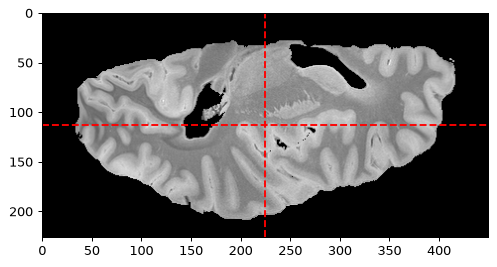

In [7]:
mri_path = os.path.join(CASE_DIR, "mri_rotated", "mri.nii.gz")
mri = nib.load(mri_path)
print("MRI shape", mri.shape, "voxel size", np.round(mri.header.get_zooms()[:3], 3), "mm")

n = np.array(mri.shape[:3])
corners = np.array(list(itertools.product(*[(-0.5, s - 0.5) for s in n])))   # same lines as the script
ras = corners @ mri.affine[:3, :3].T + mri.affine[:3, 3]
# print(corners)
# # print(mri.affine[:3, 3])
# print(ras)
lo, hi = ras.min(0), ras.max(0)
# print(lo, hi)
print("field of view in mm: from", np.round(lo, 2), "to", np.round(hi, 2), "-> size", np.round(hi - lo, 1))

for res in (0.4, 0.2, 0.1):
    s, a = V1.target_grid(mri_path, res)
    print(f"  --res {res}: grid {s}, {np.prod(s)/1e6:6.0f} M voxels, {np.prod(s)*2/1e9:.1f} GB as uint16")

shape, affine = V1.target_grid(mri_path, RES)
print("\naffine of the 0.2 mm grid:\n", np.round(affine, 3))



# Center of the bounding box in RAS coordinates
center_ras = (lo + hi) / 2
# Convert from RAS to voxel coordinates of the original MRI
A = mri.affine[:3, :3]  # Rotation and scaling
t = mri.affine[:3, 3]   # Translation

center_vox = np.linalg.inv(A) @ (center_ras - t)

print("Center in voxel space:", center_vox)
print("img shape:", mri.shape)
plt.imshow(mri.get_fdata()[:, :, mri.shape[2] // 2], cmap='gray')

# Without .T, the horizontal axis corresponds to voxel j,
# and the vertical axis corresponds to voxel i.
plt.axvline(center_vox[1], color='r', linestyle='--')
plt.axhline(center_vox[0], color='r', linestyle='--')

plt.show()


At 0.2 mm the grid has 333 M voxels. At 0.1 mm it would have 8 times more (2.7 G voxels): possible,
but the extra voxels would not contain more information along the section axis.

## 3. Where each block falls in the output grid

A block covers a small part of the grid. To avoid looking at 333 M voxels for each of the 45 blocks,
the script computes the **bounding box of the block in grid voxels** and only works inside it:
1. the 8 outer corners of the block → millimetres (block affine) → grid voxel coordinates;
2. `lo` = floor of the minimum, `hi` = ceil of the maximum + 1, clipped to the grid.

The figure shows the blocks seen from the side (sagittal view). Each polygon is the real outline of
a block; the dashed rectangle is the bounding box of the example block.

block 8: lo = [  0 484  54], hi = [411 691 544]  ->  box of (411, 207, 490) voxels = 42 M (the full grid has 333 M)


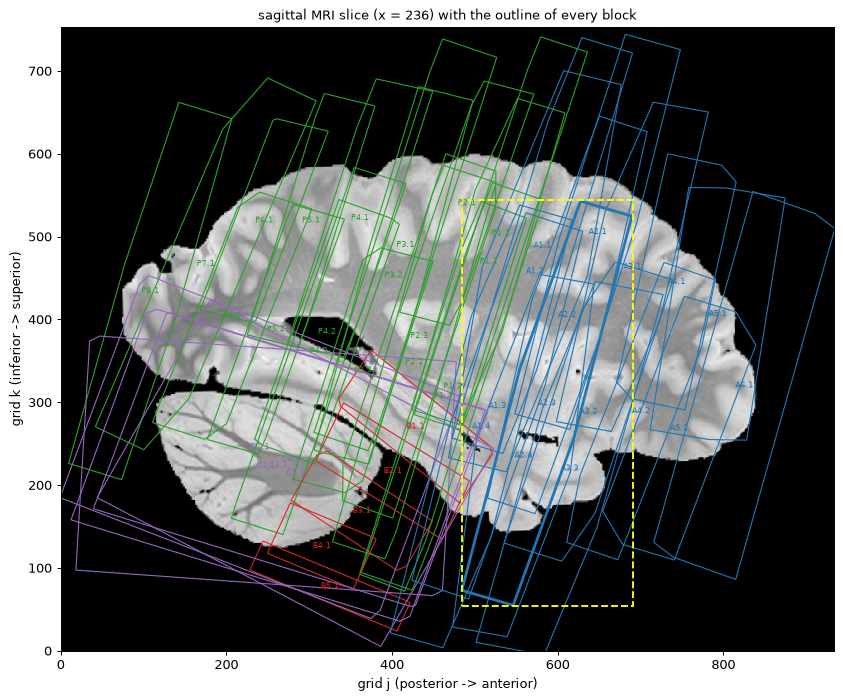

In [8]:
def block_box(img, shape, affine, res):
    """Bounding box of a block in output-grid voxels (same lines as the script)."""
    nb = np.array(img.shape[:3])
    corners = np.array(list(itertools.product(*[(-0.5, s - 0.5) for s in nb])))
    ras = corners @ img.affine[:3, :3].T + img.affine[:3, 3]
    vox = (ras - affine[:3, 3]) / res
    lo = np.clip(np.floor(vox.min(0)).astype(int), 0, shape)
    hi = np.clip(np.ceil(vox.max(0)).astype(int) + 1, 0, shape)
    return lo, hi, vox

# MRI resampled on the output grid, only for display
Mm = np.linalg.inv(mri.affine) @ affine
mri_grid = ndi.affine_transform(np.asanyarray(mri.dataobj).astype(np.float32), Mm[:3, :3], Mm[:3, 3],
                                output_shape=shape, order=1)

lo_b, hi_b, _ = block_box(img, shape, affine, RES)
print(f"block {EXAMPLE}: lo = {lo_b}, hi = {hi_b}  ->  box of {tuple(int(v) for v in hi_b - lo_b)} voxels "
      f"= {np.prod(hi_b - lo_b)/1e6:.0f} M (the full grid has {np.prod(shape)/1e6:.0f} M)")

fig, ax = plt.subplots(figsize=(13, 9))
X0 = shape[0] // 2
show_img(ax, mri_grid[X0], cmap="gray", title=f"sagittal MRI slice (x = {X0}) with the outline of every block")
for b in blocks:
    im = nib.load(os.path.join(blocks_dir, b, "LABELS.nii.gz"))
    _, _, vox = block_box(im, shape, affine, RES)
    p = vox[:, 1:]; hull = p[ConvexHull(p).vertices]
    c = letters[block_name[b][0]]
    ax.add_patch(Polygon(hull, closed=True, fill=False, ec=c, lw=2.2 if b == EXAMPLE else 0.9))
    ax.text(*p.mean(0), block_name[b], color=c, fontsize=6, ha="center", va="center")
ax.add_patch(Rectangle((lo_b[1], lo_b[2]), hi_b[1] - lo_b[1], hi_b[2] - lo_b[2], fill=False, ec="yellow", ls="--", lw=1.5))
ax.set_xlabel("grid j (posterior -> anterior)"); ax.set_ylabel("grid k (inferior -> superior)")
ax.set_xlim(0, shape[1]); ax.set_ylim(0, shape[2])
plt.show()

What the figure shows:
- Each polygon is one **block** seen from its edge. The **cerebrum blocks** (A and P, blue and
  green) look like thin strips, almost vertical but **tilted** about 15-20°: they are ~1 cm thick
  (the thickness of their slab) and their sections are stacked from back to front.
- The **brainstem blocks** (B, red) are cut in another orientation, and the **cerebellum blocks**
  (C, purple) are cut sagittally, so from the side they are seen face-on and look like large areas.
- Blocks of the same slab (for example A2.1 … A2.4, the four pieces of slab A2) are at the same
  antero-posterior position, so in this side view their outlines fall **on top of each other**. A
  side view cannot separate them; the coronal view below can.
- The bounding box (yellow) is much larger than the block because the block is tilted. Most voxels
  of the box are outside the block; step 4 discards them.

### The same blocks seen from the front (coronal)

Two cuts through the centre of the example block, coloured by the block that has tissue at each
pixel (the MRI is behind, in grey):
- **(a)** a true coronal plane of the output grid;
- **(b)** a plane that follows the slab of the example block, i.e. the plane of its middle section.

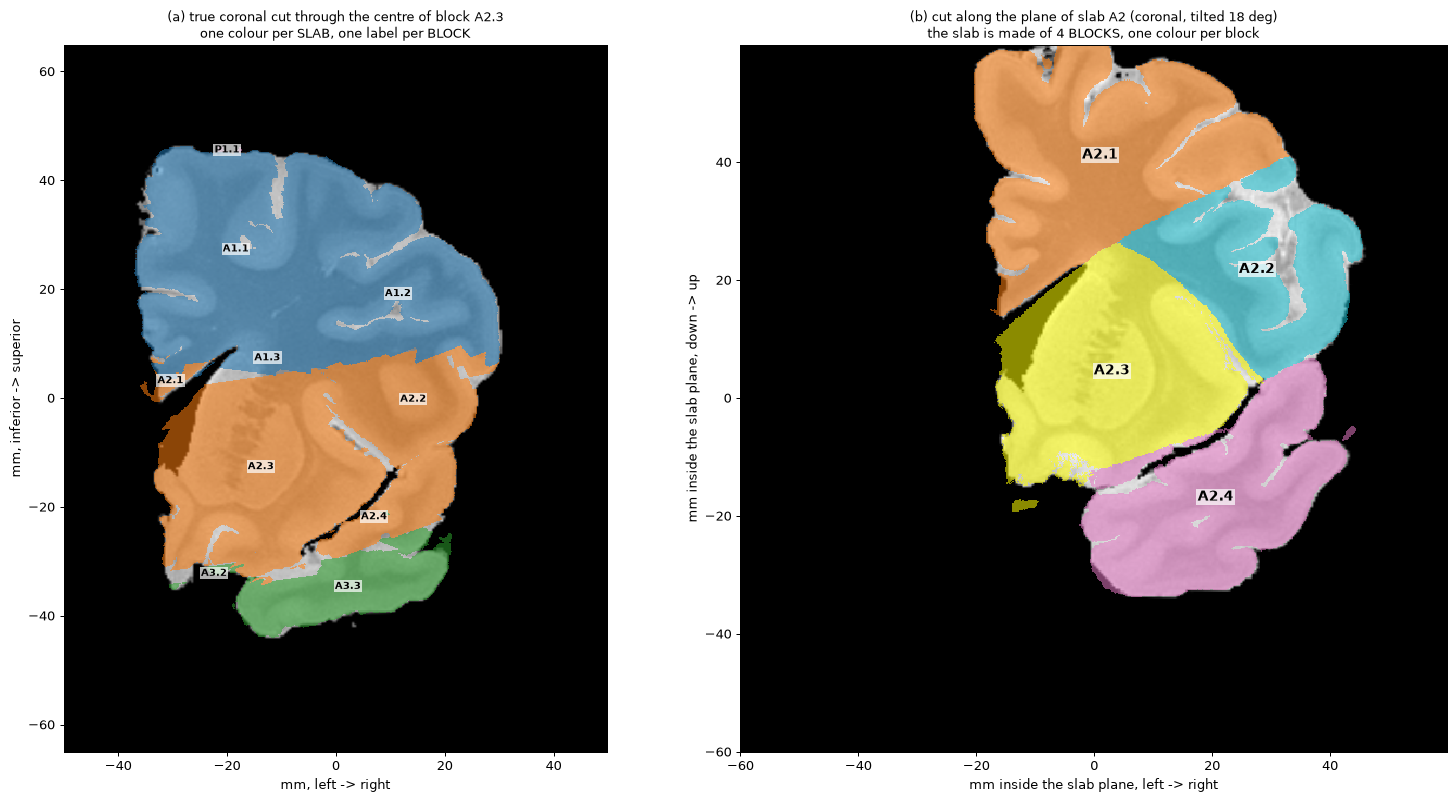

In [9]:
def cut_plane(origin, e1, e2, half=(50, 65), step=RES):
    """Sample a plane of the MRI space. Returns the mm position of every pixel, shape (nu, nv, 3)."""
    u = np.arange(-half[0], half[0], step); v = np.arange(-half[1], half[1], step)
    return origin + u[:, None, None] * e1 + v[None, :, None] * e2, u, v

def blocks_on_plane(P, which):
    """For every pixel of the plane: index (in `which`) of the block that has tissue there, -1 if none."""
    owner = np.full(P.shape[:2], -1)
    for n, b in enumerate(which):
        im = nib.load(os.path.join(blocks_dir, b, "LABELS.nii.gz")); L = np.asanyarray(im.dataobj)
        inv = np.linalg.inv(im.affine)
        idx = np.rint(P @ inv[:3, :3].T + inv[:3, 3]).astype(int)          # mm -> nearest block voxel
        ok = np.all((idx >= 0) & (idx < np.array(L.shape[:3])), axis=-1)
        ok[ok] = L[tuple(idx[ok].T)] > 0                                    # only where there is tissue
        owner[ok & (owner < 0)] = n
    return owner

def mri_on_plane(P):
    inv = np.linalg.inv(mri.affine)
    return ndi.map_coordinates(np.asanyarray(mri.dataobj).astype(np.float32),
                               np.moveaxis(P @ inv[:3, :3].T + inv[:3, 3], -1, 0), order=1)

def draw_blocks(ax, owner, which, u, v, colors, fs=8):
    ext = [u[0], u[-1], v[0], v[-1]]
    rgba = np.zeros(owner.T.shape + (4,))
    for n, b in enumerate(which):
        m = owner.T == n
        if not m.any(): continue
        rgba[m] = (*plt.matplotlib.colors.to_rgb(colors[n]), 0.55)
        vv, uu = ndi.center_of_mass(m)
        ax.text(u[int(uu)], v[int(vv)], block_name[b], fontsize=fs, ha="center", va="center", weight="bold",
                bbox=dict(fc="w", ec="none", alpha=0.7, pad=1))
    ax.imshow(rgba, origin="lower", extent=ext, interpolation="nearest")

slab = block_name[EXAMPLE].split(".")[0]                                   # "A2"
same_slab = sorted((b for b in blocks if block_name[b].split(".")[0] == slab), key=lambda b: block_name[b])
centre = img.affine @ np.append((np.array(img.shape[:3]) - 1) / 2, 1)      # centre of the example block, mm
centre = centre[:3]
R, A, S = np.eye(3)

# (a) true coronal plane (constant A) through the centre of the example block, all 45 blocks
Pa, ua, va = cut_plane(centre * [0, 1, 0] + (affine[:3, 3] + RES * np.array(shape) / 2) * [1, 0, 1], R, S)
order = sorted(blocks, key=lambda b: block_name[b])
slabs = sorted({block_name[b].split(".")[0] for b in blocks})
tab = plt.cm.tab10(np.arange(10))
own_a = blocks_on_plane(Pa, order)

# (b) plane of the slab: the plane of the middle section of the example block (tilted coronal)
nrm = np.cross(img.affine[:3, 0], img.affine[:3, 1]); nrm /= np.linalg.norm(nrm)
e1 = R - (R @ nrm) * nrm; e1 /= np.linalg.norm(e1)                         # "left-right" inside the plane
e2 = np.cross(nrm, e1); e2 *= np.sign(e2 @ S)                              # "down-up" inside the plane
Pb, ub, vb = cut_plane(centre, e1, e2, half=(60, 60))
own_b = blocks_on_plane(Pb, same_slab)

fig, axs = plt.subplots(1, 2, figsize=(17, 9))
show_img(axs[0], mri_on_plane(Pa), extent=[ua[0], ua[-1], va[0], va[-1]], cmap="gray",
         title=f"(a) true coronal cut through the centre of block {block_name[EXAMPLE]}\none colour per SLAB, one label per BLOCK")
draw_blocks(axs[0], own_a, order, ua, va, [tab[slabs.index(block_name[b].split('.')[0]) % 10] for b in order])
axs[0].set_xlabel("mm, left -> right"); axs[0].set_ylabel("mm, inferior -> superior")
show_img(axs[1], mri_on_plane(Pb), extent=[ub[0], ub[-1], vb[0], vb[-1]], cmap="gray",
         title=f"(b) cut along the plane of slab {slab} (coronal, tilted {np.degrees(np.arccos(abs(nrm @ A))):.0f} deg)\n"
               f"the slab is made of {len(same_slab)} BLOCKS, one colour per block")
draw_blocks(axs[1], own_b, same_slab, ub, vb, ["tab:orange", "tab:cyan", "yellow", "tab:pink", "tab:olive", "tab:red"], fs=11)
axs[1].set_xlabel("mm inside the slab plane, left -> right"); axs[1].set_ylabel("mm inside the slab plane, down -> up")
plt.tight_layout(); plt.show()

How to read it:
- **(b) is one slab.** The whole coronal slice of the hemisphere is slab A2, and the coloured
  pieces are its four blocks A2.1 … A2.4, side by side like the pieces of a puzzle. Each piece is
  one `LABELS.nii.gz`. The sections of a block are parallel to this picture and stacked towards
  the reader.
- **(a) crosses several slabs.** The slabs are tilted about 18° with respect to the grid, so a
  vertical coronal plane does not stay inside one slab: it goes through slab A1 at the top, A2 in
  the middle and A3 at the bottom (one colour per slab). The horizontal borders between colours are
  the knife cuts between slabs; the borders between labels of the same colour are the cuts between
  blocks.
- The thin grey gaps between blocks are places where no block has a label. The script does not
  fill them (step 7 comes back to these gaps).

## 4. From an output voxel to a block voxel

For each output voxel inside the bounding box the script asks: **which block voxel is at this
position?** Both affines go to the same millimetre space, so

```
M = inverse(block affine) @ grid affine          # grid voxel -> block voxel
(cx, cy, cz) = M @ (i, j, k, 1)                  # continuous block coordinates
idx = round(cx, cy, cz)                          # nearest block voxel
```

- `cx, cy` are positions inside a section (0.1 mm pixels), `cz` is the position along the stack,
  in units of sections. `round(cz)` is **the nearest section**.
- The output voxel is `inside` the block if the three rounded indices exist in the block array.
- `dist = |cz - round(cz)| * dz` is the distance in mm from the output voxel to the section it
  copies. It is at most half the section spacing. It is kept to resolve overlaps (step 6).

Example: one line of output voxels crossing the block from back to front.

M (grid voxel -> block voxel):
 [[ 1.32700e+00 -4.76000e-01 -1.42200e+00  7.94044e+02]
 [ 1.46300e+00  3.17000e-01  1.32700e+00 -3.88367e+02]
 [ 1.20000e-02  2.65000e-01 -8.40000e-02 -1.24045e+02]
 [ 0.00000e+00  0.00000e+00  0.00000e+00  1.00000e+00]]

The third row says how the section coordinate changes: one step along grid j moves 0.265 sections
-> one section every 3.8 output voxels along j.

output voxels (i=205, j, k=299):
    j |    cx      cy     cz  | section  inside  dist(mm)  label
  549 |  379.3  482.4  -0.91 |    -1   False   0.07     0 
  550 |  378.8  482.7  -0.64 |    -1   False   0.26     0 
  551 |  378.4  483.0  -0.38 |     0   True    0.27     79 putamen
  552 |  377.9  483.4  -0.11 |     0   True    0.08     79 putamen
  553 |  377.4  483.7   0.15 |     0   True    0.11     79 putamen
  554 |  376.9  484.0   0.42 |     0   True    0.30     79 putamen
  555 |  376.5  484.3   0.68 |     1   True    0.23     79 putamen
  556 |  376.0  484.6   0.95 |     1   True    0

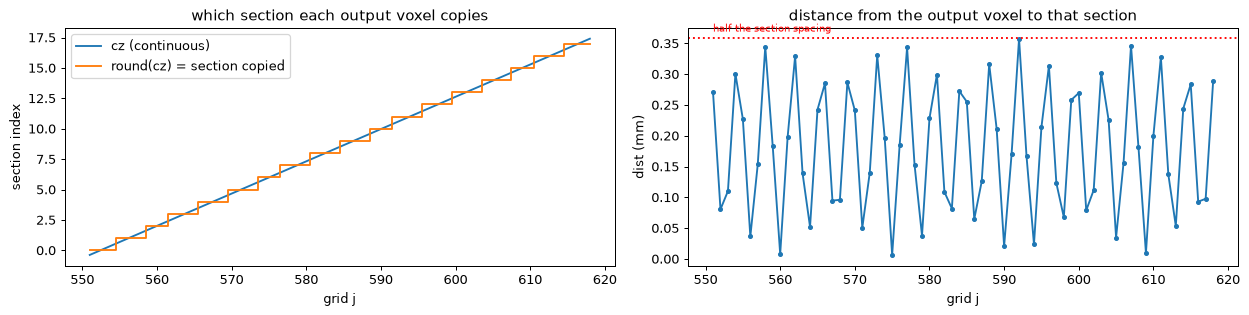

In [10]:
M = np.linalg.inv(img.affine) @ affine
print("M (grid voxel -> block voxel):\n", np.round(M, 3))
print("\nThe third row says how the section coordinate changes: one step along grid j moves "
      f"{M[2, 1]:.3f} sections\n-> one section every {1/abs(M[2, 1]):.1f} output voxels along j.\n")

nb = np.array(lab.shape)
ctr = (lo_b + hi_b) // 2
j = np.arange(lo_b[1], hi_b[1])
c = np.stack([M[r, 0] * ctr[0] + M[r, 1] * j + M[r, 2] * ctr[2] + M[r, 3] for r in range(3)], 1)
idx = np.rint(c).astype(int)
inside = np.all((idx >= 0) & (idx < nb), axis=1)
dist = np.abs(c[:, 2] - idx[:, 2]) * dz

print(f"output voxels (i={ctr[0]}, j, k={ctr[2]}):")
print("    j |    cx      cy     cz  | section  inside  dist(mm)  label")
first = np.flatnonzero(inside)[0]
for q in range(first - 2, first + 10):
    l = lab[tuple(idx[q])] if inside[q] else 0
    print(f"  {j[q]:3d} | {c[q,0]:6.1f} {c[q,1]:6.1f} {c[q,2]:6.2f} | {idx[q,2]:5d}   {str(inside[q]):5s}   {dist[q]:.2f}     {l} {NAMES.get(int(l), '') if l else ''}")

fig, axs = plt.subplots(1, 2, figsize=(14, 3.6))
axs[0].plot(j[inside], c[inside, 2], "-", label="cz (continuous)"); axs[0].step(j[inside], idx[inside, 2], where="mid", label="round(cz) = section copied")
axs[0].set_xlabel("grid j"); axs[0].set_ylabel("section index"); axs[0].legend(); axs[0].set_title("which section each output voxel copies")
axs[1].plot(j[inside], dist[inside], ".-"); axs[1].axhline(dz / 2, color="r", ls=":"); axs[1].text(j[inside][0], dz / 2 + 0.01, "half the section spacing", color="r", fontsize=8)
axs[1].set_xlabel("grid j"); axs[1].set_ylabel("dist (mm)"); axs[1].set_title("distance from the output voxel to that section")
plt.tight_layout(); plt.show()

The left plot is the origin of the **staircase** that is visible in the result: the true position
along the stack changes continuously, but the label is copied from the nearest section, so 3-4
consecutive output voxels get exactly the same section and then it jumps to the next one.

### What exactly is repeated

The drawing shows the first rows of the table above, seen from the edge of the block. The thick
vertical bars are the sections: the only places where there is real data, one every 0.72 mm. The
boxes are the output voxels of the line: one every 0.2 mm of the grid, which is 0.19 mm along the
stack because the block is tilted. About 3.8 output voxels fit between two sections, and none of
them has data of its own.

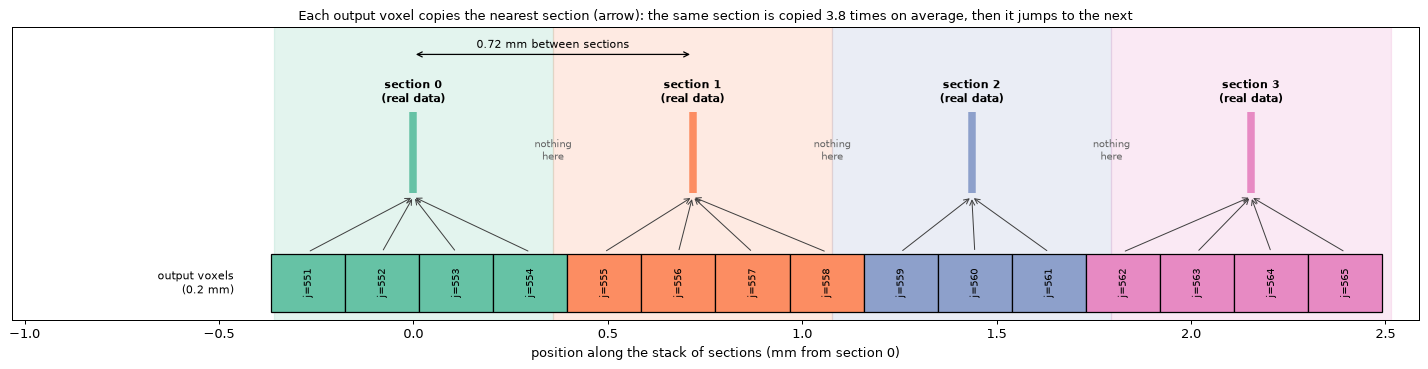

In [11]:
# Drawing of the same line of output voxels, seen from the edge of the block (real numbers of the table above).
sel = np.flatnonzero(inside)[:15]
pos = c[sel, 2] * dz                              # position of each output voxel along the stack (mm from section 0)
sec = idx[sel, 2]                                 # section copied by each output voxel
step = abs(M[2, 1]) * dz                          # distance between two consecutive output voxels along the stack
col = plt.cm.Set2(np.arange(8))

fig, ax = plt.subplots(figsize=(16, 4.2))
for s in np.unique(sec):
    ax.axvspan((s - 0.5) * dz, (s + 0.5) * dz, color=col[s], alpha=0.18)      # zone that is nearer to section s
    ax.plot([s * dz] * 2, [1.55, 2.6], color=col[s], lw=6, solid_capstyle="butt")
    ax.text(s * dz, 2.68, f"section {s}\n(real data)", ha="center", va="bottom", fontsize=9, weight="bold")
    if s > sec.min():
        ax.text((s - 0.5) * dz, 2.1, "nothing\nhere", ha="center", va="center", fontsize=8, color="0.4")
for p, s, jj in zip(pos, sec, j[sel]):
    ax.add_patch(Rectangle((p - step / 2, 0), step, 0.75, fc=col[s], ec="k"))
    ax.text(p, 0.375, f"j={jj}", rotation=90, ha="center", va="center", fontsize=8)
    ax.annotate("", xy=(s * dz, 1.5), xytext=(p, 0.78), arrowprops=dict(arrowstyle="->", color="0.25", lw=0.8))
ax.text(pos[0] - step, 0.375, "output voxels\n(0.2 mm)", ha="right", va="center", fontsize=9)
ax.annotate("", xy=(sec.min() * dz, 3.35), xytext=((sec.min() + 1) * dz, 3.35), arrowprops=dict(arrowstyle="<->"))
ax.text((sec.min() + 0.5) * dz, 3.4, f"{dz:.2f} mm between sections", ha="center", va="bottom", fontsize=9)
ax.set_xlim(pos[0] - 4 * step, pos[-1] + step); ax.set_ylim(-0.1, 3.7); ax.set_yticks([])
ax.set_xlabel("position along the stack of sections (mm from section 0)")
ax.set_title("Each output voxel copies the nearest section (arrow): the same section is copied "
             f"{dz / step:.1f} times on average, then it jumps to the next", fontsize=10)
plt.tight_layout(); plt.show()

Each output voxel copies the label of the nearest section (arrows), so **the same section image
is copied identically into 3 or 4 consecutive layers of output voxels**; when the next section
becomes nearer, the output jumps to it. Structures do not change smoothly between sections: they
stay frozen for a few layers and then jump. This is the staircase. In the blocks with sections
every 0.33 mm the step is half as high (about 1.7 layers), so it is less visible.

## 5. Resampling one whole block

The script does the same computation for all the voxels of the bounding box at once (with numpy
broadcasting, in chunks of `--chunk` slabs to limit memory). The function below is the body of the
loop of the script, without the chunks.

In [12]:
def resample_block_v1(img, shape, affine, res):
    """Nearest-neighbour resampling of one block inside its bounding box (as in the script).
    Returns the box (tuple of slices), the labels and the through-plane distance (inf outside)."""
    lab = np.asanyarray(img.dataobj)
    if lab.ndim == 2:
        lab = lab[..., None]
    nb = np.array(lab.shape[:3])
    dz = float(np.linalg.norm(img.affine[:3, 2]))
    lo, hi, _ = block_box(img, shape, affine, res)
    M = np.linalg.inv(img.affine) @ affine
    ii = np.arange(lo[0], hi[0], dtype=np.float32)[:, None, None]
    jj = np.arange(lo[1], hi[1], dtype=np.float32)[None, :, None]
    kk = np.arange(lo[2], hi[2], dtype=np.float32)[None, None, :]
    c = [M[r, 0] * ii + M[r, 1] * jj + M[r, 2] * kk + M[r, 3] for r in range(3)]
    idx = [np.rint(x).astype(np.int32) for x in c]
    inside = np.ones(idx[0].shape, dtype=bool)
    for a in range(3):
        inside &= (idx[a] >= 0) & (idx[a] < nb[a])
    dist = (np.abs(c[2] - idx[2]) * dz).astype(np.float32)
    dist[~inside] = np.inf
    vals = np.zeros(inside.shape, dtype=np.uint16)
    vals[inside] = lab[idx[0][inside], idx[1][inside], idx[2][inside]]
    return tuple(slice(a, b) for a, b in zip(lo, hi)), vals, dist

t0 = time.time()
box, vals, dist3 = resample_block_v1(img, shape, affine, RES)
print(f"block {EXAMPLE}: box {vals.shape}, {np.isfinite(dist3).mean()*100:.0f}% of the box is inside the block, "
      f"{(vals > 0).sum()} labelled voxels, {time.time()-t0:.1f} s")

block 8: box (411, 207, 490), 17% of the box is inside the block, 1556579 labelled voxels, 1.4 s


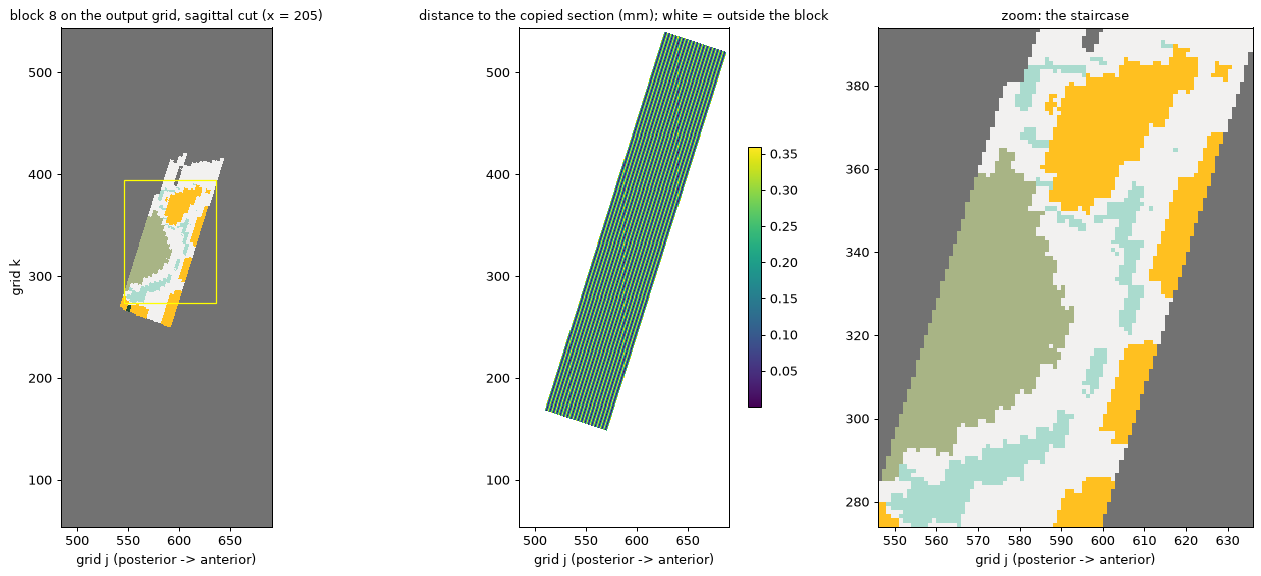

In [10]:
ix = vals.shape[0] // 2
ext = [box[1].start, box[1].stop, box[2].start, box[2].stop]
fig, axs = plt.subplots(1, 3, figsize=(15, 6.5), gridspec_kw=dict(width_ratios=[1, 1.15, 1.5]))
show_lab(axs[0], vals[ix], ext, f"block {EXAMPLE} on the output grid, sagittal cut (x = {box[0].start + ix})")
d = np.where(np.isfinite(dist3[ix]), dist3[ix], np.nan)
im = show_img(axs[1], d, ext, "distance to the copied section (mm); white = outside the block", cmap="viridis")
plt.colorbar(im, ax=axs[1], fraction=0.035)
# zoom
fg = np.argwhere(vals[ix] > 0); cj, ck = np.median(fg, 0).astype(int)
zj, zk = slice(max(cj - 45, 0), cj + 45), slice(max(ck - 60, 0), ck + 60)
show_lab(axs[2], vals[ix][zj, zk], [ext[0] + zj.start, ext[0] + zj.stop, ext[2] + zk.start, ext[2] + zk.stop], "zoom: the staircase")
axs[0].add_patch(Rectangle((ext[0] + zj.start, ext[2] + zk.start), 90, 120, fill=False, ec="yellow"))
for ax in axs: ax.set_xlabel("grid j (posterior -> anterior)")
axs[0].set_ylabel("grid k")
plt.tight_layout(); plt.show()

- Left: the block is a tilted slab about 13 mm thick. Compare with the section images of step 1:
  this is the stack seen from the side, now in the MRI space.
- Middle: the distance map has one stripe per section (zero on the section, maximum half-way
  between two sections).
- Right: every section is extruded over 3-4 voxels and boundaries move in steps. This is the
  **staircase** artefact of nearest-neighbour sampling along the stack.

Also note the last stripes of the block: if a section is **empty or only partly labelled** in the
block file, the output is empty there too. The script copies what the file has.

## 6. Overlapping blocks: who wins

Neighbouring blocks overlap a little in the output grid, because the bounding slabs are tilted and
the blocks were registered independently. For a voxel claimed by two blocks the script keeps the
label **whose section is closest** to the voxel (smallest `dist`). It needs two full-size arrays:

```
seg  : the labels written so far
best : the dist of the label written so far (starts at infinity)

take = (vals > 0) & (dist < best)     # labelled in this block AND closer than what is there
seg[take]  = vals[take]
best[take] = dist[take]
```

Two details:
- `vals > 0`: background of a block never overwrites anything. A hole in one block can be covered
  by the neighbouring block.
- The original `3d-recon-all-labels.py` of the ERC_reconstruction repository has no `best`: the
  last block processed overwrites the previous ones. The result then depends on the order of the
  blocks.

Example with the example block and the block in front of / behind it.

In [11]:
OTHER = "45"
img2 = nib.load(os.path.join(blocks_dir, OTHER, "LABELS.nii.gz"))
box2, vals2, dist2 = resample_block_v1(img2, shape, affine, RES)

# put both blocks in one small canvas (union of the two boxes)
ulo = [min(a.start, b.start) for a, b in zip(box, box2)]; uhi = [max(a.stop, b.stop) for a, b in zip(box, box2)]
ushape = tuple(h - l for l, h in zip(ulo, uhi))
def to_canvas(bx, arr, fill):
    out = np.full(ushape, fill, arr.dtype)
    out[tuple(slice(s.start - l, s.stop - l) for s, l in zip(bx, ulo))] = arr
    return out
A, dA = to_canvas(box, vals, 0), to_canvas(box, dist3, np.inf)
B, dB = to_canvas(box2, vals2, 0), to_canvas(box2, dist2, np.inf)

both = (A > 0) & (B > 0)
closest = np.where((B > 0) & ((A == 0) | (dB < dA)), B, A)      # rule of the script
last = np.where(B > 0, B, A)                                    # "last block wins"
print(f"block {EXAMPLE} ({block_name[EXAMPLE]}): {(A > 0).sum()} voxels; block {OTHER} ({block_name[OTHER]}): {(B > 0).sum()} voxels")
print(f"claimed by both: {both.sum()} voxels ({both.sum()*RES**3/1000:.2f} cm3); the two blocks disagree on the label in "
      f"{(A[both] != B[both]).mean()*100:.0f}% of them")
print(f"voxels where 'closest section wins' and 'last block wins' give a different label: {(closest != last).sum()}")

block 8 (A2.3): 1556579 voxels; block 45 (A1.3): 2318939 voxels
claimed by both: 36209 voxels (0.29 cm3); the two blocks disagree on the label in 51% of them
voxels where 'closest section wins' and 'last block wins' give a different label: 4729


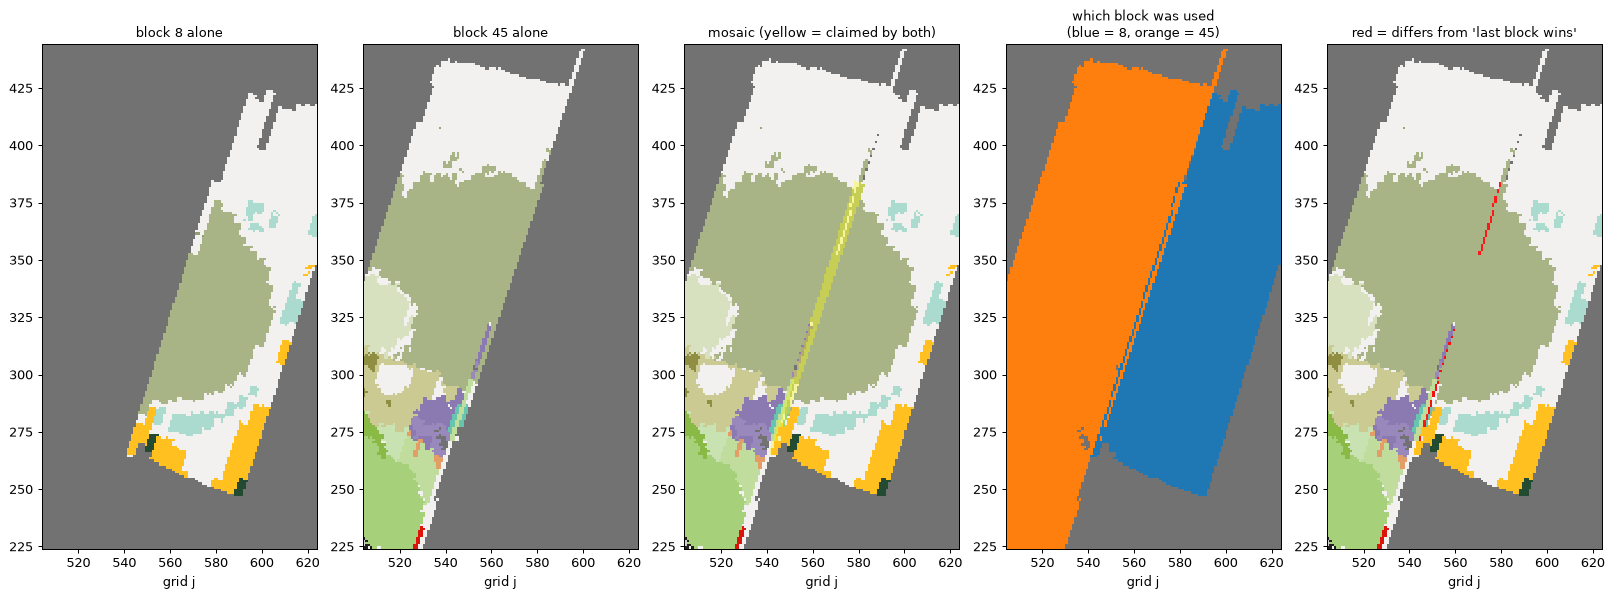

In [12]:
ix = int(np.argmax(both.sum(axis=(1, 2))))          # sagittal slice with the largest overlap
uext = [ulo[1], uhi[1], ulo[2], uhi[2]]
fg = np.argwhere(both[ix]); cj, ck = np.median(fg, 0).astype(int)
zj, zk = slice(max(cj - 60, 0), cj + 60), slice(max(ck - 110, 0), ck + 110)
zext = [uext[0] + zj.start, uext[0] + zj.stop, uext[2] + zk.start, uext[2] + zk.stop]
fig, axs = plt.subplots(1, 5, figsize=(18, 6.5))
show_lab(axs[0], A[ix][zj, zk], zext, f"block {EXAMPLE} alone")
show_lab(axs[1], B[ix][zj, zk], zext, f"block {OTHER} alone")
show_lab(axs[2], closest[ix][zj, zk], zext, "mosaic, closest section wins"); overlay(axs[2], both[ix][zj, zk], "yellow", zext, 0.35)
axs[2].set_title("mosaic (yellow = claimed by both)", fontsize=10)
src = np.where(closest[ix] == 0, 0, np.where((B[ix] > 0) & ((A[ix] == 0) | (dB[ix] < dA[ix])), 2, 1))
show_img(axs[3], src[zj, zk], zext, f"which block was used\n(blue = {EXAMPLE}, orange = {OTHER})",
         cmap=plt.matplotlib.colors.ListedColormap([BG, "tab:blue", "tab:orange"]), vmin=0, vmax=2)
show_lab(axs[4], closest[ix][zj, zk], zext, "red = differs from 'last block wins'"); overlay(axs[4], (closest != last)[ix][zj, zk], "red", zext)
for ax in axs: ax.set_xlabel("grid j")
plt.tight_layout(); plt.show()

In the overlap the two blocks interleave: each voxel takes the block that has a section nearer to
it. Where the two blocks do not agree (they were registered independently), the boundary between
them shows a small jump. This is the **block step** artefact; the script does not correct it.

## 7. The complete result and its limitations

The script repeats steps 3-6 for the 45 blocks and saves `seg` as a `uint16` NIfTI with the grid
affine. The label values are the NextBrain IDs (`3dAtlas/lut.freeview.txt`).

```bash
python build_3d_segmentation.py --case-dir ../NextBrain-Case-1/P57-16 --res 0.2
# -> outputs/P57-16_seg_0.2mm.nii.gz      (about 45 s)
```

The cell below loads the file produced by that command.

In [13]:
seg = np.asanyarray(nib.load(OUT_V1).dataobj)
ids, cnt = np.unique(seg, return_counts=True)
print("grid", seg.shape, "|", len(ids) - 1, "labels |", f"{cnt[1:].sum()*RES**3/1000:.1f} cm3 labelled")
print("\nlargest labels:")
for q in np.argsort(cnt[1:])[::-1][:8] + 1:
    print(f"  {ids[q]:5d} {NAMES.get(int(ids[q]), '?'):45s} {cnt[q]*RES**3/1000:7.1f} cm3")
print("smallest labels:")
for q in np.argsort(cnt[1:])[:4] + 1:
    print(f"  {ids[q]:5d} {NAMES.get(int(ids[q]), '?'):45s} {cnt[q]*RES**3:7.2f} mm3")

grid (473, 934, 753) | 333 labels | 516.5 cm3 labelled

largest labels:
      7 white_matter_of_forebrain                       171.4 cm3
   2028 ctx-rh-superiorfrontal                           25.6 cm3
    595 molecular_layer_of_pva                           21.1 cm3
    597 granular_cell_layer_of_pva                       19.1 cm3
   2024 ctx-rh-precentral                                17.6 cm3
   2027 ctx-rh-rostralmiddlefrontal                      17.2 cm3
   2008 ctx-rh-inferiorparietal                          15.2 cm3
   2022 ctx-rh-postcentral                               12.8 cm3
smallest labels:
    647 nucleus_of_trapezoid_body                        0.15 mm3
    535 root_of_trochlear_nerve                          0.37 mm3
    190 magnocellular_division_of_reticular_nucleus      0.41 mm3
    443 dorsal_division_of_central_lateral_nucleus       0.43 mm3


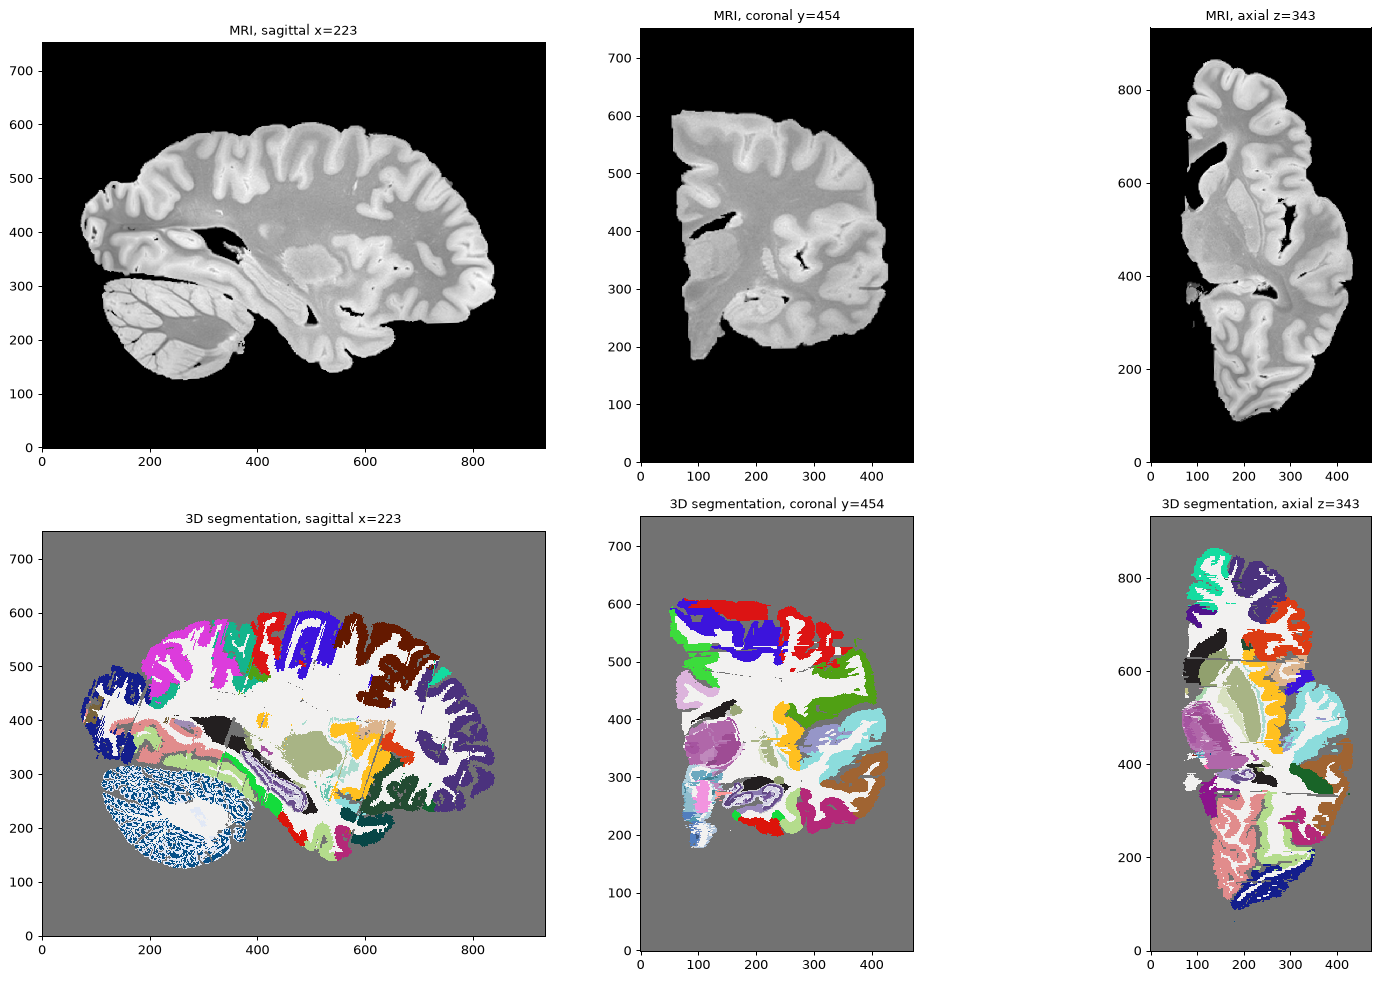

In [14]:
fgx = np.nonzero((seg > 0).any(axis=(1, 2)))[0]; fgy = np.nonzero((seg > 0).any(axis=(0, 2)))[0]; fgz = np.nonzero((seg > 0).any(axis=(0, 1)))[0]
SX, SY, SZ = int(np.percentile(fgx, 45)), int(fgy.mean()), int(fgz.mean())
fig, axs = plt.subplots(2, 3, figsize=(17, 11))
for col, (name, m2, s2) in enumerate([(f"sagittal x={SX}", mri_grid[SX], seg[SX]), (f"coronal y={SY}", mri_grid[:, SY], seg[:, SY]),
                                      (f"axial z={SZ}", mri_grid[:, :, SZ], seg[:, :, SZ])]):
    show_img(axs[0, col], m2, title="MRI, " + name, cmap="gray"); show_lab(axs[1, col], s2, title="3D segmentation, " + name)
plt.tight_layout(); plt.show()

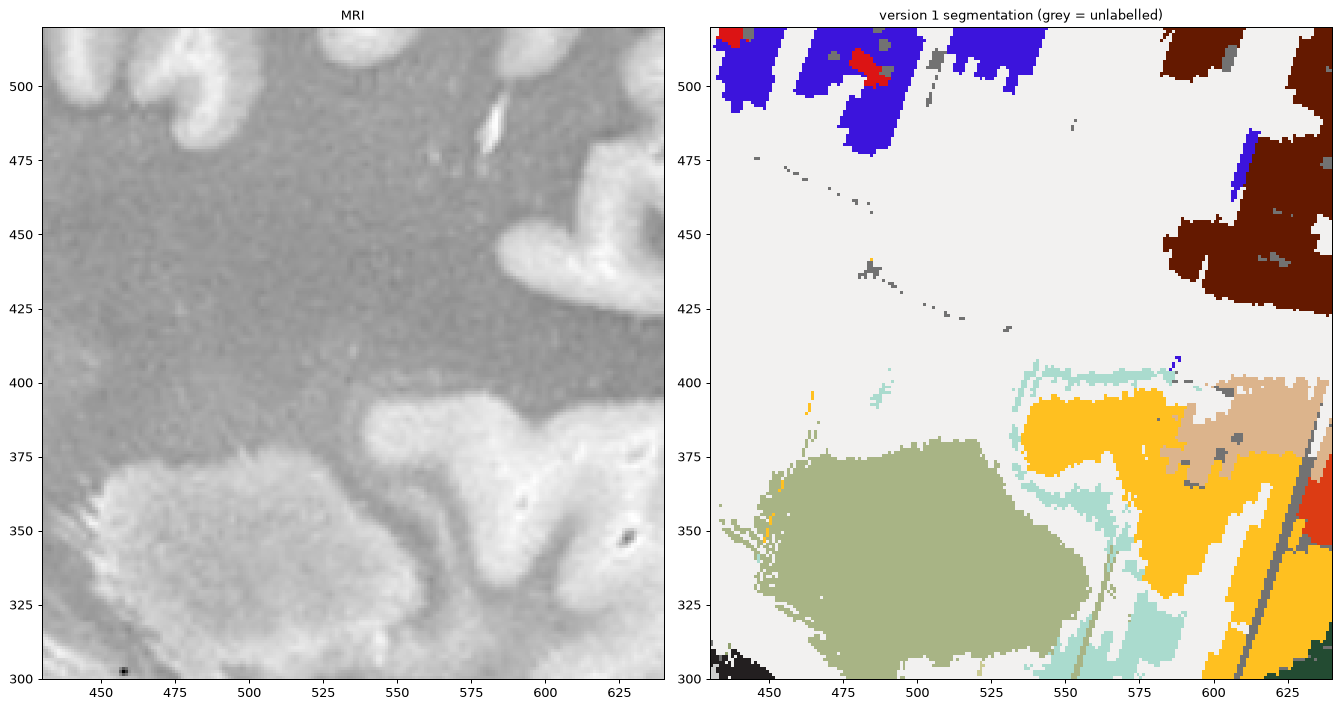

In [15]:
# zoom on a sagittal region to see the artefacts
ZJ, ZK = slice(430, 640), slice(300, 520)
fig, axs = plt.subplots(1, 2, figsize=(15, 8))
show_img(axs[0], mri_grid[SX][ZJ, ZK], [ZJ.start, ZJ.stop, ZK.start, ZK.stop], "MRI", cmap="gray")
show_lab(axs[1], seg[SX][ZJ, ZK], [ZJ.start, ZJ.stop, ZK.start, ZK.stop], "version 1 segmentation (grey = unlabelled)")
plt.tight_layout(); plt.show()

In the zoom: the tilted grey line on the right is a **block gap** (the unlabelled last sections of a
block), the grey dots inside the white matter are small **holes** copied from the sections, and the
boundaries of the structures move in small steps (**staircase**).

### What version 1 does well and what it does not

It is a faithful copy of the registered sections: no label is invented, all the labels of the case
are present, and it takes less than a minute.

Its limitations all come from "copy the nearest section":

| artefact | where it comes from |
|---|---|
| **staircase** along the section axis | each section is repeated over 2-4 output voxels (step 4) |
| **block gaps**: thin unlabelled sheets between blocks | the first/last sections of a block are often empty or partly labelled, and the script copies them as they are (step 5) |
| **block steps** | each block was registered independently; the script trusts the affines (step 6) |
| **holes and cracks** inside tissue | tears and unlabelled areas in the histology sections are copied |
| labels outside the brain | the script never looks at the MRI intensities, only at its field of view |

`build_3d_segmentation_v2.py` addresses the first two and the last one. See
`build_3d_segmentation_v2_explained.ipynb`.